In [1]:
import os
import json
import logging
import warnings
from typing import Dict, List, Tuple

import numpy as np
import torch
import matplotlib.pyplot as plt
from dotenv import load_dotenv
import time

from gluonts.itertools import batcher
from gluonts.model.forecast import QuantileForecast

from gift_eval.data import Dataset
from uni2ts.model.moiraic import MoiraicForecast, MoiraicModule
from uni2ts.model.moiraie import MoiraieForecast, MoiraieModule
from uni2ts.model.moirai2 import Moirai2Forecast, Moirai2Module
from uni2ts.model.moiraix import MoiraiXForecast, MoiraiXModule
from timesfm.pretrain import TimesFMXForecast, TimesFMXModule
from chronos import BaseChronosPipeline

load_dotenv()
logging.getLogger("gluonts.model.forecast").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.facecolor": "white",
})
print("Imports complete.")

Imports complete.


In [12]:
# ============================================================
# CONFIGURATION — list as many models as you want to compare
# ============================================================

# Each entry: display name -> dict with checkpoint info
MODELS = {
    "moiraix_enc_cpm_arcsinh": {
        "path": "/srv/disk00/ctadler/uni2ts/outputs/pretrain/moiraix/gift_eval_pretrain_trackb_p30_nosde_gift/moiraix_enc_cpm_arcsinh_0/HF_checkpoints/last",
        "checkpoint_type": "hf",
    },
    "moiraix_dec_ntp_arcsinh": {
        "path": "/srv/disk00/ctadler/uni2ts/outputs/pretrain/moiraix/gift_eval_pretrain_trackb_p30_nosde_gift/moiraix_dec_ntp_arcsinh_0/HF_checkpoints/last",
        "checkpoint_type": "hf",
    },
    "timesfmx_trackb_p30_nosde_gift": {
        "path": "/srv/disk00/ctadler/timesfm/outputs/pretrain/timesfmx_baseline/gift_eval_pretrain_trackb_p30_nosde_gift/timesfmx_trackb_p30_nosde_gift_0/HF_checkpoints/last",
        "checkpoint_type": "hf",
    },
    "moiraic_11": {
        "path": "/srv/disk00/ctadler/uni2ts/outputs/pretrain/moiraic/gift_eval_pretrain_weighted/moiraic_training_11/HF_checkpoints/last",
        "checkpoint_type": "hf",
    },
    "moirai2": {
        "path": "Salesforce/moirai-2.0-R-small",
        "checkpoint_type": "hf",
    },
    "chronos2": {
        "path": "amazon/chronos-2",
        "checkpoint_type": "hf",
    },
}

# --- Datasets to compare on ---
# List of (dataset_name, term) pairs. Term is "short", "medium", or "long".
COMPARISON_TARGETS = [
    ("bizitobs_application", "medium"),
    ("bizitobs_l2c/5T",   "medium"),
    ("bizitobs_l2c/H",   "medium"),
    # ("bizitobs_l2c/H",  "long"),
    ("bizitobs_service",   "medium"),
    # ("bizitobs_service",   "medium"),
    # ("bizitobs_service",  "long"),
    ("covid_deaths", "medium"),
    # ("electricity/15T", "short"),
    ("electricity/H", "medium"),
    ("electricity/W", "short"),
    # ("ett2/H", "long"),
    # ("ett2/15T", "short"),
    # ("ett2/W", "short"),
    # ("LOOP_SEATTLE/5T", "long"),
    # ("LOOP_SEATTLE/5T", "medium"),
    ("LOOP_SEATTLE/H", "medium"),
    # ("m4_hourly", "short"),
    # ("m4_weekly", "short"),
    ("M_DENSE/D", "short"),
    ("M_DENSE/H", "medium"),
    ("solar/10T", "medium"),
    ("solar/H", "medium"),
    ("kdd_cup_2018_with_missing/H", "medium"),
    # ("solar/10T", "medium"),
    # ("solar/10T", "long"),
    # ("solar/W", "short"),
    ("us_births/D", "short"),
    ("us_births/M", "short"),
    ("us_births/W", "short"),
]

# --- Inference ---
CONTEXT_LENGTH = 4000
BATCH_SIZE = 32
QUANTILE_LEVELS = (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)
DEVICE = "cuda:2"   # "auto", "cuda", "cpu", "cuda:N"

# --- Visualization ---
NUM_SERIES_TO_PLOT = 4          # how many series per (dataset, term)
CONTEXT_POINTS_TO_SHOW = 200    # historical points before forecast start
MAX_PRED_LEN = 64
VIZ_SEED = 42                   # reproducible series selection
SHARE_Y_ACROSS_MODELS = True    # share y-axis across models for fair visual compare

# Pretty name mapping
PRETTY_NAMES = {
    "saugeenday": "saugeen",
    "temperature_rain_with_missing": "temperature_rain",
    "kdd_cup_2018_with_missing": "kdd_cup_2018",
    "car_parts_with_missing": "car_parts",
}

# Color per model (cycled if you add more)
MODEL_COLORS = ["#1f77b4", "#a02c2c", "#9467bd", "#ff7f0e", "#8c564b", "#2ca02c"]

dataset_properties_map = json.load(
    open("/srv/disk00/ctadler/gift-eval/notebooks/dataset_properties.json")
)
print(f"Configured {len(MODELS)} model(s) on {len(COMPARISON_TARGETS)} (dataset, term) pair(s).")

Configured 6 model(s) on 16 (dataset, term) pair(s).


## Setup

In [5]:
def get_device(device="auto"):
    if device == "auto":
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")
    return torch.device(device)

def infer_model_type(name: str) -> str:
    if "chronos2" in name or "chronos-2" in name: return "chronos2"
    if "timesfmx" in name: return "timesfmx"
    if "moiraic" in name: return "moiraic"
    if "moiraie" in name: return "moiraie"
    if "moiraix" in name: return "moiraix"
    if "moirai2" in name: return "moirai"
    return "moiraix"

MODULE_CLS   = {"moiraic": MoiraicModule,   "moiraie": MoiraieModule,   "moirai": Moirai2Module, "moiraix": MoiraiXModule, "timesfmx": TimesFMXModule}
FORECAST_CLS = {"moiraic": MoiraicForecast, "moiraie": MoiraieForecast, "moirai": Moirai2Forecast, "moiraix": MoiraiXForecast, "timesfmx": TimesFMXForecast}

def load_module(model_name: str, model_path: str, checkpoint_type: str = "hf", device=None):
    mtype = infer_model_type(model_name)
    if mtype == "chronos2":
        # Chronos-2 ships as a pipeline, not a bare nn.Module — load it directly
        # onto its device rather than moving it later like the Moirai family.
        module = BaseChronosPipeline.from_pretrained(
            model_path, device_map=str(device) if device is not None else "auto"
        )
        print(f"  ✔ Loaded {model_name} (chronos2) from {model_path}")
        return module, mtype
    Mod = MODULE_CLS[mtype]
    if checkpoint_type == "hf":
        module = Mod.from_pretrained(model_path)
    elif checkpoint_type == "ckpt":
        module = Mod.load_from_checkpoint(model_path)
    else:
        raise ValueError(f"Unknown checkpoint_type {checkpoint_type!r}")
    print(f"  ✔ Loaded {model_name} ({mtype}) from {model_path}")
    return module, mtype

device = get_device(DEVICE)
print(f"Using device: {device}\nLoading modules...")

LOADED = {}   # name -> (module, model_type)
for name, cfg in MODELS.items():
    LOADED[name] = load_module(name, cfg["path"], cfg.get("checkpoint_type", "hf"), device=device)
print("All modules loaded.")

Using device: cuda:2
Loading modules...
Loading weights from local directory
  ✔ Loaded moiraix_enc_cpm_arcsinh (moiraix) from /srv/disk00/ctadler/uni2ts/outputs/pretrain/moiraix/gift_eval_pretrain_trackb_p30_nosde_gift/moiraix_enc_cpm_arcsinh_0/HF_checkpoints/last
Loading weights from local directory
  ✔ Loaded moiraix_dec_ntp_arcsinh (moiraix) from /srv/disk00/ctadler/uni2ts/outputs/pretrain/moiraix/gift_eval_pretrain_trackb_p30_nosde_gift/moiraix_dec_ntp_arcsinh_0/HF_checkpoints/last
Loading weights from local directory
  ✔ Loaded timesfmx_trackb_p30_nosde_gift (timesfmx) from /srv/disk00/ctadler/timesfm/outputs/pretrain/timesfmx_baseline/gift_eval_pretrain_trackb_p30_nosde_gift/timesfmx_trackb_p30_nosde_gift_0/HF_checkpoints/last
Loading weights from local directory
  ✔ Loaded moiraic_11 (moiraic) from /srv/disk00/ctadler/uni2ts/outputs/pretrain/moiraic/gift_eval_pretrain_weighted/moiraic_training_11/HF_checkpoints/last
  ✔ Loaded moirai2 (moirai) from Salesforce/moirai-2.0-R-small

In [6]:
cnt = 0
class MoiraiQuantilePredictor:
    """Wraps a Moirai-family forecast model for quantile prediction."""
    def __init__(self, module, model_type, prediction_length,
                 context_length=4000, target_dim=1,
                 feat_dynamic_real_dim=0, past_feat_dynamic_real_dim=0,
                 device=torch.device("cpu"), batch_size=128,
                 quantile_levels=(0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9)):
        self.prediction_length = prediction_length
        self.context_length    = context_length
        self.device            = device
        self.batch_size        = batch_size
        self.quantile_levels   = quantile_levels

        ForecastCls = FORECAST_CLS.get(model_type, MoiraiXForecast)
        forecast_dict = {
            "module": module,
            "prediction_length": prediction_length,
            "context_length": context_length,
            "target_dim": target_dim,
            "feat_dynamic_real_dim": feat_dynamic_real_dim,
            "past_feat_dynamic_real_dim": past_feat_dynamic_real_dim,
            # "ar_method": "naive",
        }
        # global cnt
        # # print(cnt)
        # # if (model_type == "moiraic"):
        # if (cnt % 4) == 0:
        #     forecast_dict["ar_method"] = "naive"
        # if (cnt % 4) == 1:
        #     forecast_dict["ar_method"] = "branch"
        # if (cnt % 4) == 2:
        #     forecast_dict["ar_method"] = "trajectory"
        #     forecast_dict["ar_u_scheme"] = "iid"
        #     forecast_dict["ar_num_trajectories"] = 128
        # cnt += 1
        # print(f"{model_type}: {forecast_dict}")
        self.model = ForecastCls(
            **forecast_dict
        ).to(self.device)

    def predict(self, test_data_input):
        tot_time = 0
        bs = self.batch_size
        while True:
            try:
                chunks = []
                for batch in batcher(test_data_input, batch_size=bs):
                    past_target = [e["target"] for e in batch]
                    time_start = time.time()
                    chunks.append(self.model.predict(past_target))
                    tot_time += time.time() - time_start
                forecast_quantiles = np.concatenate(chunks)
                break
            except torch.cuda.OutOfMemoryError:
                bs //= 2
                if bs < 1: raise
                print(f"  OOM — reducing batch_size to {bs}")

        out = []
        for arr, ts in zip(forecast_quantiles, test_data_input):
            start = ts["start"] + len(ts["target"])
            out.append(QuantileForecast(
                item_id=ts["item_id"],
                forecast_arrays=arr,
                start_date=start,
                forecast_keys=list(map(str, self.quantile_levels)),
            ))
        # print(f"Total Prediction time: {tot_time:.3} seconds {self.model.ar_method} {self.model.ar_u_scheme}, {self.model.ar_num_trajectories}")
        return out

print("Predictor class defined.")

Predictor class defined.


In [7]:
class ChronosQuantilePredictor:
    """Wraps a Chronos-2 pipeline for quantile prediction (same .predict()
    interface as MoiraiQuantilePredictor, for interchangeable use above)."""
    def __init__(self, pipeline, prediction_length, batch_size=128,
                 quantile_levels=(0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9)):
        self.pipeline = pipeline
        self.prediction_length = prediction_length
        self.batch_size = batch_size
        self.quantile_levels = list(quantile_levels)

    def predict(self, test_data_input):
        bs = self.batch_size
        while True:
            try:
                chunks = []
                for batch in batcher(test_data_input, batch_size=bs):
                    inputs = [{"target": np.asarray(e["target"], dtype=np.float32)} for e in batch]
                    quantiles, _ = self.pipeline.predict_quantiles(
                        inputs=inputs,
                        prediction_length=self.prediction_length,
                        quantile_levels=self.quantile_levels,
                    )
                    # each series comes back as [variates, seq_len, quantiles];
                    # stacking + permuting gives [batch, quantiles, seq_len, variates].
                    # We're always univariate here (target_dim=1), so squeeze it.
                    q = torch.stack(quantiles).permute(0, 3, 2, 1).cpu().numpy()
                    chunks.append(q.squeeze(-1))
                forecast_quantiles = np.concatenate(chunks)
                break
            except torch.cuda.OutOfMemoryError:
                bs //= 2
                if bs < 1: raise
                print(f"  OOM — reducing batch_size to {bs}")

        out = []
        for arr, ts in zip(forecast_quantiles, test_data_input):
            start = ts["start"] + len(ts["target"])
            out.append(QuantileForecast(
                item_id=ts["item_id"],
                forecast_arrays=arr,
                start_date=start,
                forecast_keys=list(map(str, self.quantile_levels)),
            ))
        return out

print("Chronos-2 predictor class defined.")

Chronos-2 predictor class defined.


In [8]:
def resolve_ds_config(ds_name: str, term: str):
    if "/" in ds_name:
        ds_key, ds_freq = ds_name.split("/", 1)
        ds_key = PRETTY_NAMES.get(ds_key.lower(), ds_key.lower())
    else:
        ds_key = PRETTY_NAMES.get(ds_name.lower(), ds_name.lower())
        ds_freq = dataset_properties_map[ds_key]["frequency"]
    return ds_key, ds_freq, f"{ds_key}/{ds_freq}/{term}"


QUANTILE_PAIRS = [(0.1, 0.9), (0.2, 0.8), (0.3, 0.7), (0.4, 0.6)]
BAND_ALPHAS    = [0.12,        0.20,        0.30,        0.40]

def _plot_one(ax, context, ground_truth, forecast, color, title,
              context_points=200, show_legend=False, pred_len=None):
    ctx = context[-context_points:]
    pred_len = len(ground_truth) if pred_len == None else min(len(ground_truth), pred_len)
    x_ctx = np.arange(-len(ctx), 0)
    x_fct = np.arange(0, pred_len)

    ax.plot(x_ctx, ctx, color="#4a4a4a", linewidth=0.8, label="Context")
    ax.plot(x_fct, ground_truth[:pred_len], color="#d62728",
            linewidth=1.0, linestyle="--", alpha=0.85, label="Ground Truth")

    for (q_lo, q_hi), alpha in zip(QUANTILE_PAIRS, BAND_ALPHAS):
        lo = forecast.quantile(q_lo)[:pred_len]
        hi = forecast.quantile(q_hi)[:pred_len]
        lbl = f"{int(q_lo*100)}–{int(q_hi*100)}%" if q_lo == 0.1 else None
        ax.fill_between(x_fct, lo, hi, color=color, alpha=alpha, label=lbl)

    median = forecast.quantile(0.5)[:pred_len]
    for i in range(0, pred_len, 64):
        ax.axvline(i, lw=0.5, ls=":", c="black")
    ax.plot(x_fct, median, color=color, linewidth=1.3, label="Median")
    ax.axvline(x=0, color="gray", linestyle=":", linewidth=0.7, alpha=0.6)
    ax.set_title(title, fontsize=10)
    ax.grid(True, alpha=0.25)


def plot_side_by_side(model_names, model_forecasts, contexts, ground_truths,
                      dataset_label, context_points=200, share_y=True, pred_len=None):
    """
    model_forecasts: dict[model_name -> list[QuantileForecast]]  (same length & order)
    contexts, ground_truths: list[np.ndarray] aligned with the forecasts
    """
    n_series = len(contexts)
    n_models = len(model_names)

    fig, axes = plt.subplots(
        n_series, n_models,
        figsize=(5.2 * n_models, 2.8 * n_series),
        squeeze=False, constrained_layout=True,
        sharey="row" if share_y else False,
    )

    fig.suptitle(f"Side-by-side forecasts — {dataset_label}",
                 fontsize=13, fontweight="bold")

    for i in range(n_series):
        for j, m in enumerate(model_names):
            color = MODEL_COLORS[j % len(MODEL_COLORS)]
            fc = model_forecasts[m][i]
            item_id = fc.item_id if fc.item_id else f"series_{i}"
            title = f"{m}\nseries: {item_id}" if i == 0 else f"series: {item_id}"
            _plot_one(
                axes[i][j], contexts[i], ground_truths[i], fc,
                color=color, title=title, context_points=context_points,
                show_legend=False, pred_len=pred_len
            )
            if j == 0:
                axes[i][j].set_ylabel("Value")
            if i == n_series - 1:
                axes[i][j].set_xlabel("Time Step")

    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=min(6, len(labels)),
               bbox_to_anchor=(0.5, -0.015), frameon=True, fontsize=8)
    plt.show()


def compute_per_series_metrics_mae(ground_truths, forecasts):
    """Quick MAE / MASE-ish per-series scores for ranking interesting examples."""
    out = []
    for gt, fc in zip(ground_truths, forecasts):
        pred_len = min(len(gt), fc.forecast_array.shape[-1])
        median = fc.quantile(0.5)[:pred_len]
        mae = float(np.mean(np.abs(gt[:pred_len] - median)))
        out.append(mae)
    return np.array(out)

def compute_per_series_metrics_wql(ground_truths, forecasts, quantiles=None):
    """Per-series weighted quantile loss (WQL) for ranking interesting examples.

    For each (gt, forecast) pair:
        QL_q(y, ŷ_q) = 2 * max(q * (y - ŷ_q), (q - 1) * (y - ŷ_q))
        WQL = sum_q sum_t QL_q(y_t, ŷ_{q,t}) / (|Q| * sum_t |y_t|)

    The factor of 2 makes QL_{0.5} reduce to |y - median|, so for a single
    quantile at q=0.5 this matches the previous MAE-style scoring up to the
    sum_t|y_t| normalization. Lower is better.
    """
    if quantiles is None:
        quantiles = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
    quantiles = np.asarray(quantiles, dtype=float)

    out = []
    for gt, fc in zip(ground_truths, forecasts):
        pred_len = min(len(gt), fc.forecast_array.shape[-1])
        y = np.asarray(gt[:pred_len], dtype=float)

        # Stack quantile predictions -> (Q, T)
        preds = np.stack([
            np.asarray(fc.quantile(float(q)))[:pred_len] for q in quantiles
        ])

        diff = y[None, :] - preds                                      # (Q, T)
        ql = 2.0 * np.maximum(
            quantiles[:, None] * diff,
            (quantiles[:, None] - 1.0) * diff,
        )                                                              # (Q, T)

        denom = np.abs(y).sum() * len(quantiles)
        wql = ql.mean()
        out.append(wql)
    return np.array(out)


print("Plotting helpers defined.")

Plotting helpers defined.


## Plots


🔍 Comparing on: bizitobs_application/10S/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
  Robot-Sh |               0.1754 |               0.1922 |               0.1471 |               0.1972 |               0.1572 |               0.1335
  Robot-Sh |               0.3663 |               0.4785 |               0.8033 |               0.4367 |               0.4307 |               0.3421
  Robot-Sh |             243.8129 |             242.52

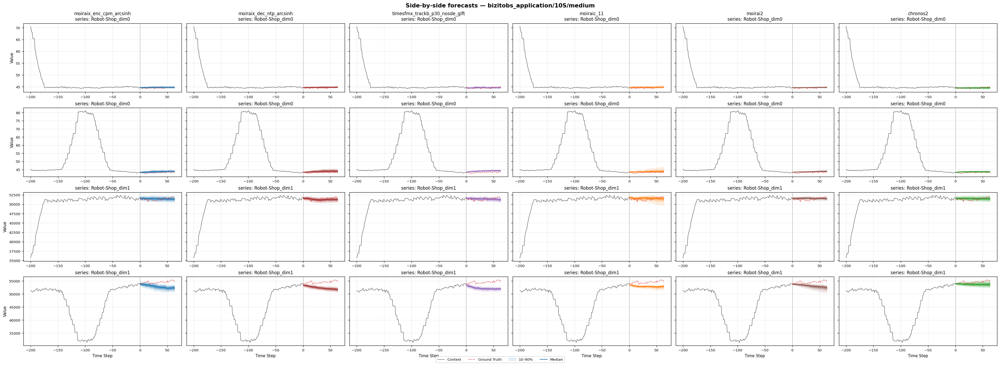


🔍 Comparing on: bizitobs_l2c/5T/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
  L2C_dim1 |               1.0404 |               3.8280 |               0.6114 |               0.6149 |               3.9635 |               0.6137
  L2C_dim2 |               1.3238 |               2.6849 |               1.7870 |               1.7059 |               1.5171 |               3.0389
  L2C_dim5 |               4.8384 |               9.9944 |     

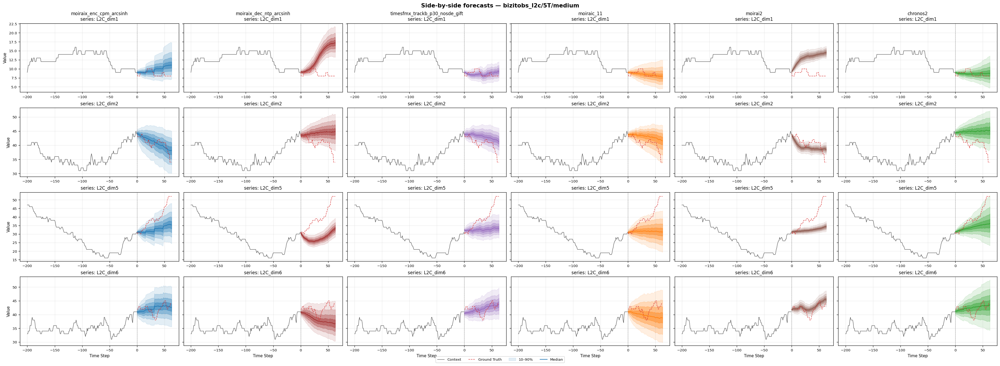


🔍 Comparing on: bizitobs_l2c/H/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
  L2C_dim0 |               0.7691 |               4.3032 |               4.9718 |              11.9387 |               0.8872 |               0.6691
  L2C_dim2 |               1.5769 |               1.7679 |               2.3441 |               3.1955 |               1.0005 |               1.5262
  L2C_dim5 |               4.8511 |               5.8105 |      

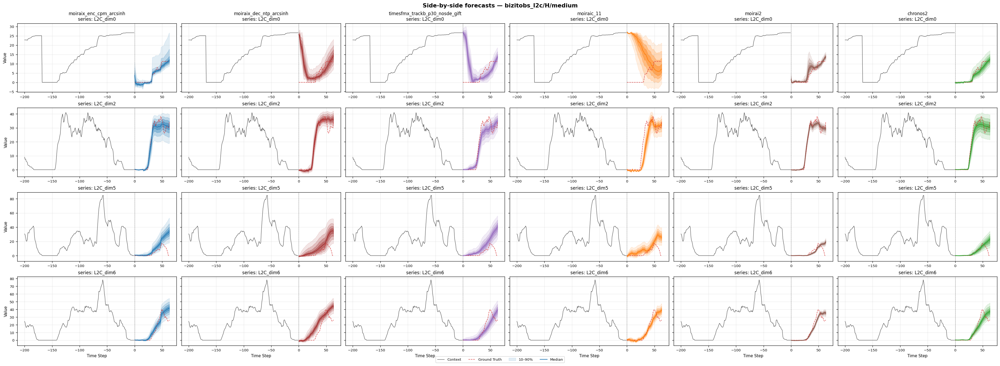


🔍 Comparing on: bizitobs_service/10S/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
  cities_d |              11.5156 |              13.7517 |              12.6399 |               9.2611 |               7.7389 |               6.0001
  dispatch |               1.8878 |               2.0911 |               1.8996 |               1.7913 |               1.6475 |               1.9718
  robot-sh |               0.0686 |               0.0727 |

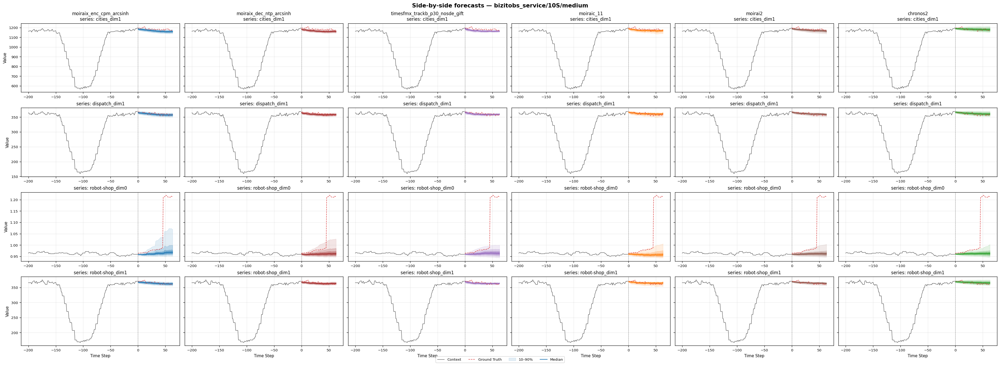


🔍 Comparing on: covid_deaths/D/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
        T5 |               7.6842 |              10.5840 |              10.2932 |               9.0746 |              10.4530 |               9.1422
       T15 |               9.6245 |               9.2509 |              10.1389 |               8.9506 |               5.9076 |              10.8826
       T91 |               3.9128 |               3.7353 |      

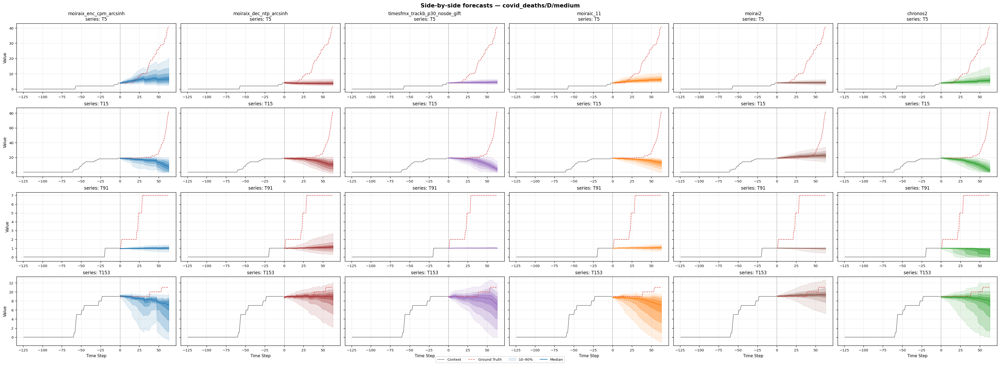


🔍 Comparing on: electricity/H/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
    MT_037 |              15.0843 |              21.1783 |              14.4023 |              20.4100 |              17.5047 |              14.7721
    MT_055 |              24.8065 |              17.8187 |              25.3034 |              23.6750 |              22.3402 |              22.1729
    MT_125 |              11.1073 |               9.8629 |       

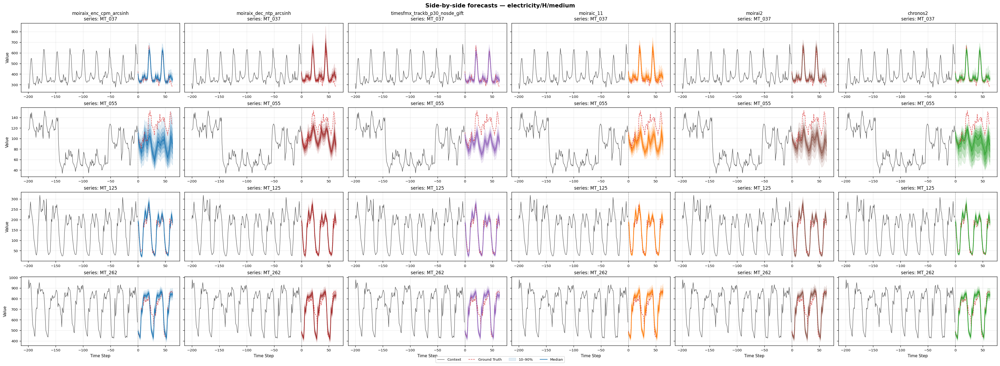


🔍 Comparing on: electricity/W/short
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
    MT_022 |            2773.3100 |            2571.8014 |            2608.0119 |            2484.5813 |            2529.8736 |            1615.0970
    MT_115 |            4996.4802 |            5405.6057 |            7688.3087 |            5467.8292 |            4290.4809 |            4469.6196
    MT_127 |            3533.4891 |            4754.5193 |        

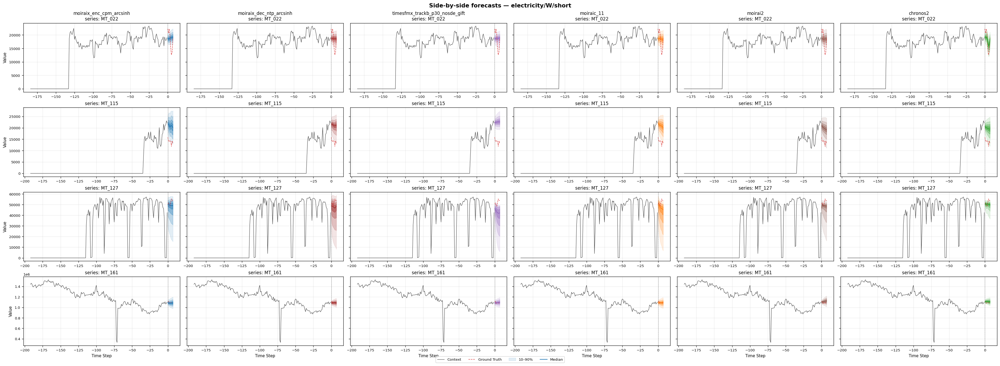


🔍 Comparing on: loop_seattle/H/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
       126 |               2.1011 |               1.8711 |               1.9872 |               2.7822 |               2.0781 |               1.8895
       194 |               4.2476 |               3.9295 |               4.2664 |               4.6431 |               4.3573 |               4.3251
       277 |               2.3249 |               2.3135 |      

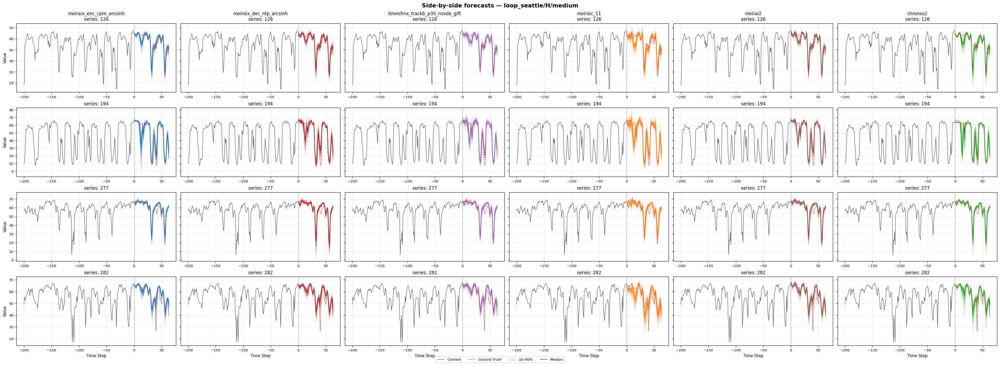


🔍 Comparing on: m_dense/D/short
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
         2 |               3.8329 |               3.9865 |               4.2821 |               4.6468 |               3.8207 |               3.4725
        25 |             108.6758 |             130.0418 |             122.6116 |             121.4240 |             112.5871 |             126.5036
        27 |              74.1588 |              78.3474 |            

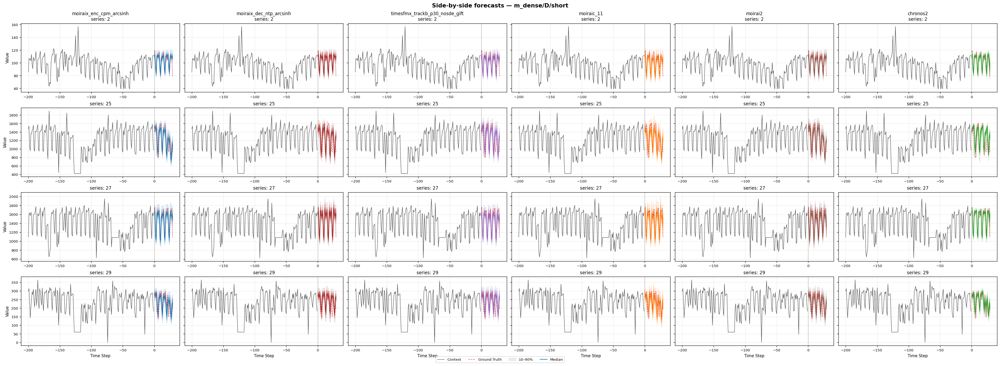


🔍 Comparing on: m_dense/H/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
         2 |              10.7296 |              11.0799 |              10.9772 |              10.8693 |              11.0067 |              10.7747
         5 |              24.6986 |              24.0164 |              20.4816 |              25.1129 |              22.6042 |              23.7933
        13 |              19.5093 |              16.5599 |           

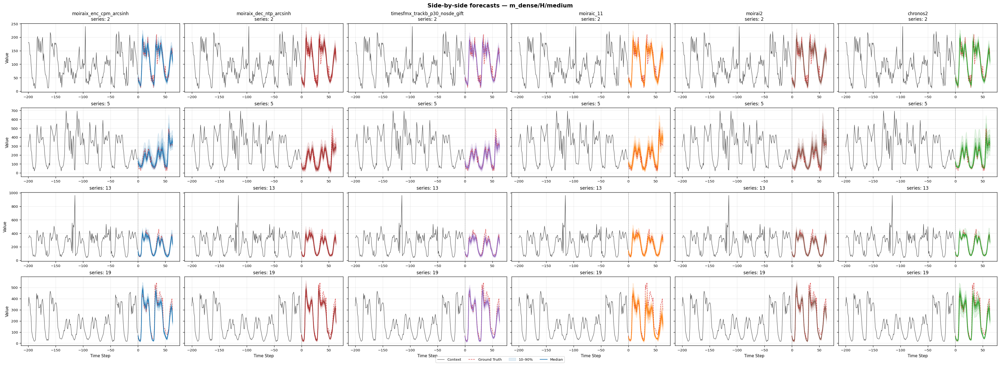


🔍 Comparing on: solar/10T/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
   item_33 |               0.0130 |               0.0315 |               0.0277 |               0.2275 |               0.0379 |               0.0512
   item_45 |               0.0645 |               0.0665 |               0.0404 |               0.5822 |               0.0738 |               0.0745
   item_73 |               0.1393 |               0.2471 |           

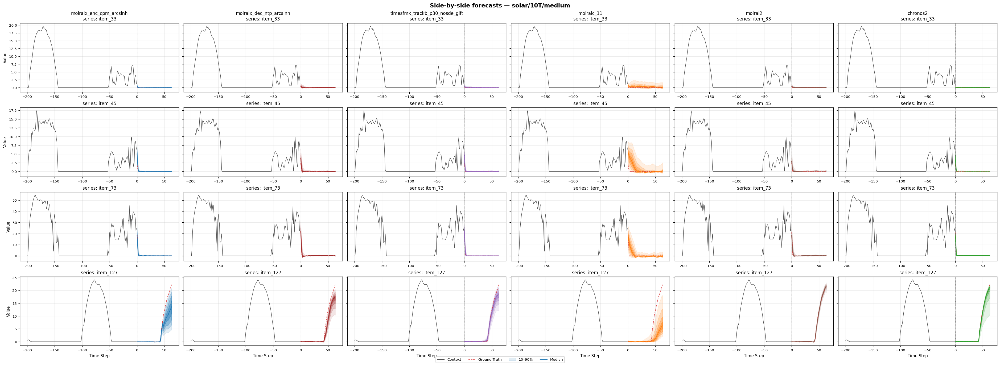


🔍 Comparing on: solar/H/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
   item_32 |               7.8934 |               8.3294 |               9.7803 |               9.0815 |               9.8090 |              10.2845
   item_57 |               6.4819 |               6.7940 |               8.7178 |               7.3786 |               7.8070 |               7.9743
   item_82 |               4.4525 |               3.3702 |             

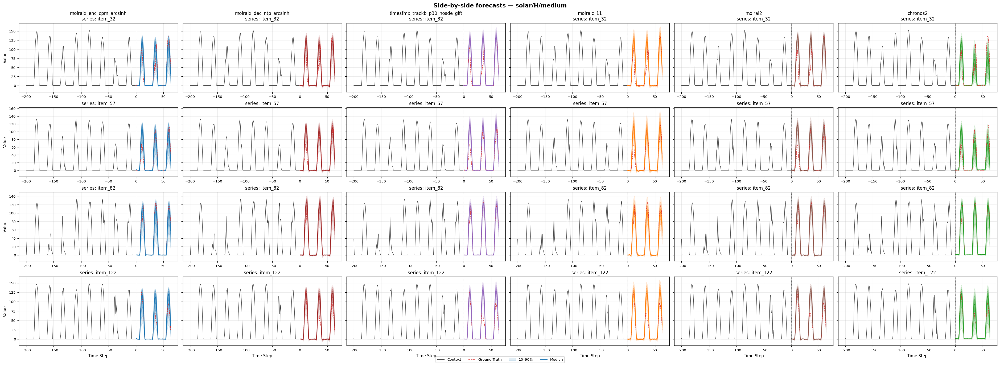


🔍 Comparing on: kdd_cup_2018/H/medium
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
        T4 |                  nan |                  nan |                  nan |                  nan |                  nan |                  nan
       T91 |                  nan |                  nan |                  nan |                  nan |                  nan |                  nan
      T127 |                  nan |                  nan |      

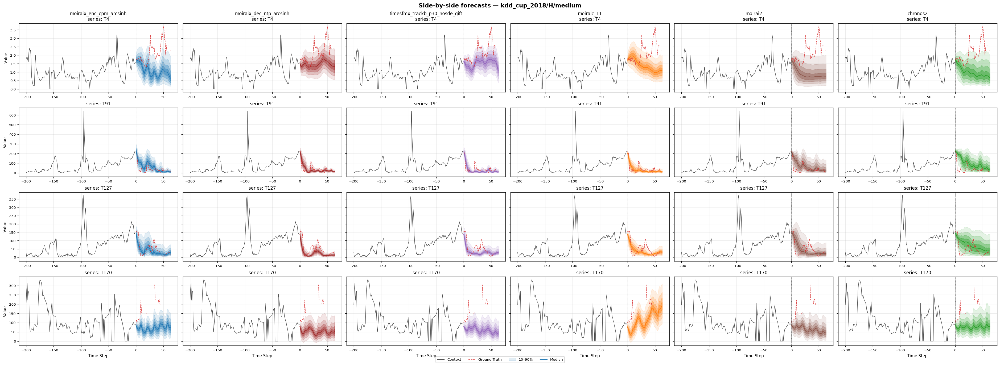


🔍 Comparing on: us_births/D/short
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
        T1 |             174.4683 |             227.4910 |             201.0578 |             194.4556 |             167.5817 |             143.6130
        T1 |             148.7109 |             174.2427 |             166.2373 |             237.7910 |             165.5766 |             142.7640
        T1 |             216.2973 |             271.9717 |          

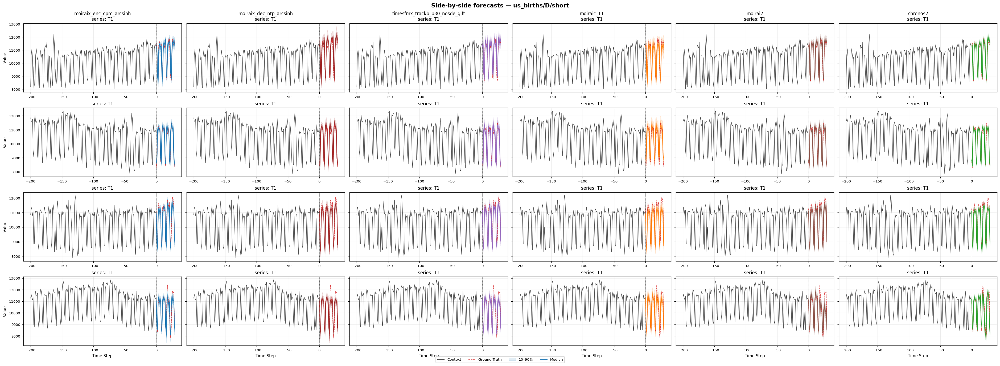


🔍 Comparing on: us_births/M/short
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
        T1 |            4913.1629 |           10604.3525 |            5143.3105 |            5534.0594 |            6123.7159 |            4998.4263
        T1 |            5775.5627 |            5832.5679 |            4640.3390 |            6380.0050 |            4739.4604 |            3063.4658


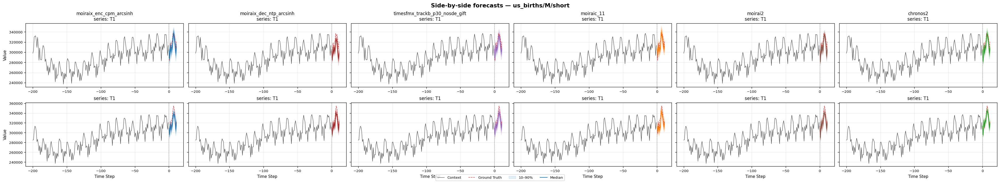


🔍 Comparing on: us_births/W/short
  → predicting with moiraix_enc_cpm_arcsinh
  → predicting with moiraix_dec_ntp_arcsinh
  → predicting with timesfmx_trackb_p30_nosde_gift
  → predicting with moiraic_11
  → predicting with moirai2
  → predicting with chronos2

  Per-series median WQL (lower is better):
  series  | moiraix_enc_cpm_arcsinh | moiraix_dec_ntp_arcsinh | timesfmx_trackb_p30_nosde_gift |           moiraic_11 |              moirai2 |             chronos2
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------
        T1 |             631.5102 |             580.2093 |             617.1191 |             672.8065 |             538.1042 |             521.4170
        T1 |            1296.5887 |             682.9282 |             720.7296 |             673.1512 |             572.3237 |             722.7503
        T1 |            1287.3247 |            1103.0952 |          

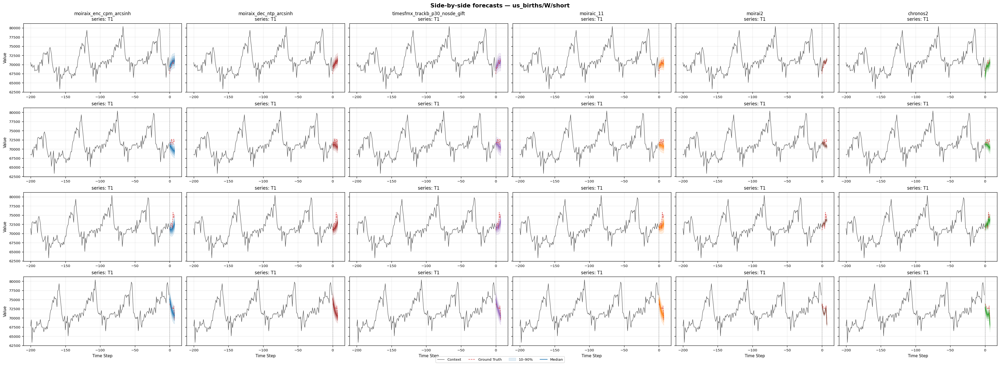

In [13]:
rng = np.random.RandomState(VIZ_SEED)
pred_len = 64

for ds_name, term in COMPARISON_TARGETS:
    ds_key, ds_freq, ds_config = resolve_ds_config(ds_name, term)
    print(f"\n🔍 Comparing on: {ds_config}")

    # Build the dataset (same exact inputs/labels for every model)
    to_univariate = Dataset(name=ds_name, term=term, to_univariate=False).target_dim != 1
    dataset = Dataset(name=ds_name, term=term, to_univariate=to_univariate)

    test_inputs = list(dataset.test_data.input)
    test_labels = list(dataset.test_data.label)
    total_series = len(test_inputs)

    n_plot = min(NUM_SERIES_TO_PLOT, total_series)
    selected_idx = sorted(rng.choice(total_series, size=n_plot, replace=False))
    sel_inputs = [test_inputs[i] for i in selected_idx]
    sel_labels = [test_labels[i] for i in selected_idx]

    # Extract context + ground truth (shared across models)
    contexts, ground_truths = [], []
    for inp, lbl in zip(sel_inputs, sel_labels):
        ctx = np.asarray(inp["target"])
        if ctx.ndim > 1: ctx = ctx[0]
        gt = np.asarray(lbl["target"])
        if gt.ndim > 1:  gt = gt[0]
        contexts.append(ctx)
        ground_truths.append(gt[:MAX_PRED_LEN])

    # Run each model
    model_forecasts: Dict[str, List[QuantileForecast]] = {}
    for mname, (module, mtype) in LOADED.items():
        print(f"  → predicting with {mname}")
        if mtype == "chronos2":
            predictor = ChronosQuantilePredictor(
                pipeline=module,
                prediction_length=min(dataset.prediction_length, MAX_PRED_LEN),
                batch_size=BATCH_SIZE,
                quantile_levels=QUANTILE_LEVELS,
            )
        else:
            predictor = MoiraiQuantilePredictor(
                module=module,
                model_type=mtype,
                prediction_length=min(dataset.prediction_length, MAX_PRED_LEN),
                context_length=CONTEXT_LENGTH,
                target_dim=1,
                past_feat_dynamic_real_dim=dataset.past_feat_dynamic_real_dim,
                device=device,
                batch_size=BATCH_SIZE,
                quantile_levels=QUANTILE_LEVELS,
            )
        model_forecasts[mname] = predictor.predict(sel_inputs)

        # free memory before next model
        del predictor
        if device.type == "cuda":
            torch.cuda.empty_cache()

    # Per-series MAE table to help spot which series differ most
    print("\n  Per-series median WQL (lower is better):")
    header = "  series  | " + " | ".join(f"{m:>20s}" for m in model_forecasts)
    print(header)
    print("  " + "-" * (len(header) - 2))
    maes = {m: compute_per_series_metrics_wql(ground_truths, fcs)
            for m, fcs in model_forecasts.items()}
    for i in range(n_plot):
        item_id = model_forecasts[next(iter(model_forecasts))][i].item_id or f"#{i}"
        row = f"  {str(item_id)[:8]:>8s} | " + " | ".join(
            f"{maes[m][i]:>20.4f}" for m in model_forecasts
        )
        print(row)

    # Side-by-side plot
    plot_side_by_side(
        model_names=list(model_forecasts.keys()),
        model_forecasts=model_forecasts,
        contexts=contexts,
        ground_truths=ground_truths,
        dataset_label=ds_config,
        context_points=CONTEXT_POINTS_TO_SHOW,
        share_y=SHARE_Y_ACROSS_MODELS,
        pred_len=pred_len
    )